# Лабораторная работа № 5. Решение систем линейных алгебраических уравнений

**Дисциплина:** Высшая математика. Практикум  

## Цель работы

Самостоятельно реализовать прямой ход метода Гаусса, обратную подстановку и LU-разложение с перестановками строк; проверить правильность алгоритмов и исследовать, как обусловленность матрицы влияет на погрешность решения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 12

## 0. Исходные данные: свой вариант

Вариант $v$ определяет матрицу $5\times5$. Для построения сначала формируется трёхдиагональная матрица $B_v$:

$$
(B_v)_{ii}=3+i+\frac{v}{10},\quad i=1,\ldots,5;\qquad
(B_v)_{i,i+1}=(B_v)_{i+1,i}=-1.
$$

Остальные элементы равны нулю. Для **нечётного** $v$ берётся $A_v=B_v$; для **чётного** $v$ матрица $A_v$ получается перестановкой **первой и третьей строк** $B_v$.

Для всех вариантов точное решение одинаково:

$$
x^*=(1,\,2,\,-1,\,0,\,3)^T,\qquad b_v=A_vx^*.
$$

У чётных вариантов $a_{11}=0$. Поэтому алгоритм **без выбора ведущего элемента** должен корректно сообщить об остановке, а не пытаться делить на ноль. Это специально предусмотрено заданием.

Выберите свой вариант в следующей ячейке. **Код генератора исходных данных готов; изменять его не нужно.** Таблица всех 30 вариантов приложена отдельно в Word.

In [2]:
VARIANT = 27   # TODO: укажите выданный преподавателем номер от 1 до 30


def make_variant(v):
    """Формирует данные варианта по приложению В.4 методических указаний."""
    if not isinstance(v, (int, np.integer)) or not 1 <= v <= 30:
        raise ValueError("Номер варианта должен быть целым числом от 1 до 30.")

    diagonal = 3 + np.arange(1, 6, dtype=float) + v / 10
    B = np.diag(diagonal)
    B += np.diag(-np.ones(4), k=1) + np.diag(-np.ones(4), k=-1)

    A = B.copy()
    if v % 2 == 0:
        A[[0, 2], :] = A[[2, 0], :]

    x_exact = np.array([1., 2., -1., 0., 3.])
    b = A @ x_exact
    return A, b, x_exact


A, b, x_exact = make_variant(VARIANT)
print("Вариант:", VARIANT)
print("A =\n", A)
print("b =", b)
print("Известное точное решение x* =", x_exact)
print("Проверка ||Ax* - b||₂ =", np.linalg.norm(A @ x_exact - b))

Вариант: 27
A =
 [[ 6.7 -1.   0.   0.   0. ]
 [-1.   7.7 -1.   0.   0. ]
 [ 0.  -1.   8.7 -1.   0. ]
 [ 0.   0.  -1.   9.7 -1. ]
 [ 0.   0.   0.  -1.  10.7]]
b = [  4.7  15.4 -10.7  -2.   32.1]
Известное точное решение x* = [ 1.  2. -1.  0.  3.]
Проверка ||Ax* - b||₂ = 0.0


## 1. Метод Гаусса: обратная подстановка и прямой ход

При прямом ходе на шаге $k$ под ведущим элементом $a_{kk}$ зануляются коэффициенты с помощью преобразования

$$
m_{ik}=\frac{a_{ik}}{a_{kk}},\qquad
R_i\leftarrow R_i-m_{ik}R_k.
$$

После приведения к верхнетреугольному виду решение находится **обратной подстановкой**:

$$
x_i=\frac{b_i-\sum_{j=i+1}^{n} a_{ij}x_j}{a_{ii}}.
$$

### Задание 1

Реализуйте `back_substitution(U, b)` для верхнетреугольной матрицы $U$ и `gauss_solve(A, b, pivot=True)` для произвольной квадратной невырожденной матрицы. Требования:

- `pivot=False` — исключение **без** перестановки строк;
- `pivot=True` — **частичный выбор ведущего элемента** (по максимальному модулю в текущем столбце среди оставшихся строк);
- использовать **копию** исходной матрицы и правой части, не менять их;
- проверять размеры и ведущие элементы; при невозможности продолжить генерировать `np.linalg.LinAlgError`;
- для обратного хода вызывать **свою функцию** `back_substitution`, а не библиотечный решатель.

*Важно:* остановка при $|a_{kk}|\leq\mathrm{tol}$ означает, что **данная реализация не продолжает вычисления при выбранном пороге**. Это не всегда доказывает точную математическую вырожденность матрицы.

In [3]:
def back_substitution(U, b, tol=1e-12):
    """Возвращает x из U @ x = b для верхнетреугольной U."""
    # TODO: преобразовать данные в массивы float и проверить размеры
    U = U.astype(float, copy=True)
    b = b.astype(float, copy=True)
    n, m = U.shape

    if m != n:
        raise ValueError("Матрица коэффициентов должна быть квадратной")
    if len(b.shape) != 1:
        raise ValueError("Матрица свободных членов должна быть вектор-столбцом")
    
    
    # TODO: создать массив x
    x = np.zeros_like(b)
    
    # TODO: пройти по строкам снизу вверх
    for i in range(n - 1, 0 - 1, -1):
        # TODO: проверить диагональный элемент и вычислить очередной x[i]
        if np.abs(U[i, i]) <= tol:
            raise RuntimeError("Элемент главной диагонали равен нулю, невозможно продолжить вычисления")
        else:
            x[i] = (b[i] - sum([U[i][j] * x[j] for j in range(i + 1, n)])) / U[i, i]

    return x
            


def gauss_solve(A, b, pivot=True, tol=1e-12):
    """Возвращает решение Ax=b; pivot=True включает частичный выбор."""
    # TODO: проверить входные данные; создать копии A и b
    A = A.astype(float, copy=True)
    b = b.astype(float, copy=True)
    n, m = A.shape
    
    if m != n:
        raise ValueError("Матрица коэффициентов должна быть квадратной")
    if b.shape != (n,):
        raise ValueError("Матрица свободных членов должна быть вектор-столбцом")
    if b.size != n:
        raise ValueError("Размеры матрицы и вектора не согласованы")

    # TODO: для каждого столбца k выполнить прямой ход
    for k in range(n - 1):
        max_row_idx = k + np.argmax(np.abs(A[k:, k])) if pivot else k  
        # Ищем максимальный по модулю элемент в k-ом столбце ниже главной диагонали
        # TODO: при pivot=False проверять текущий ведущий элемент
        
        if np.abs(A[max_row_idx, k]) <= tol:
            raise RuntimeError("Матрица вырождена или плохо обусловлена")

        # TODO: при pivot=True переставить строки в A и элементы b
        if pivot and max_row_idx != k:
            A[[max_row_idx, k]] = A[[k, max_row_idx]]
            b[[max_row_idx, k]] = b[[k, max_row_idx]]

        # TODO: исключить элементы под ведущим; занулить их явно
        for i in range(k + 1, n):
            coef_m_ik = A[i, k] / A[k, k]
            A[i, k:] -= coef_m_ik * A[k, k:]
            b[i] -= coef_m_ik * b[k]
            A[i, k] = 0.0

            
    # TODO: вызвать back_substitution для верхнетреугольной системы
    return back_substitution(A, b, tol)

### Быстрая проверка алгоритма

До работы со своим вариантом проверьте реализацию на знакомой системе. Её точное решение — $(2,3,-1)^T$. Сравните оба режима Гаусса и убедитесь, что исходные массивы не изменились. Раскомментируйте строки после реализации функций.

In [4]:
A_test = np.array([
    [2.,  1., -1.],
    [-3., -1., 2.],
    [-2., 1.,  2.]
])
b_test = np.array([8., -11., -3.]).T
expected_test = np.array([2., 3., -1.])

# TODO: выполните оба режима, сравните результат с expected_test
x_without = gauss_solve(A_test, b_test, pivot=False)
x_with = gauss_solve(A_test, b_test, pivot=True)
print("Без выбора:", x_without)
print("С выбором:", x_with)
print("Невязка без выбора:", np.linalg.norm(A_test @ x_without - b_test))
print("Невязка c выбором:", np.linalg.norm(A_test @ x_with - b_test))

Без выбора: [ 2.  3. -1.]
С выбором: [ 2.  3. -1.]
Невязка без выбора: 0.0
Невязка c выбором: 8.881784197001252e-16


## 2. Исследование двух режимов на своём варианте

Различают **ошибку решения** и **невязку**:

$$
\varepsilon_{\mathrm{rel}}=
\frac{\|x-x^*\|_2}{\|x^*\|_2},\qquad
r=Ax-b,\quad \|r\|_2.
$$

### Задание 2

Для матрицы своего варианта:

1. решите систему с `pivot=False` и `pivot=True`;
2. отдельно вычислите эталонное решение `np.linalg.solve(A, b)`;
3. для успешных запусков рассчитайте относительную ошибку и норму невязки;
4. запишите результаты **в небольшую таблицу** (режим / решение / ошибка / невязка / статус);
5. если алгоритм останавливается из-за малого или нулевого ведущего элемента, запишите **«остановка: ведущий элемент»**; не подставляйте `0` вместо отсутствующего результата.

Почему для чётного номера варианта режим `pivot=False` не должен проходить первый шаг?

In [5]:
# Эталон только для проверки, не вместо собственной реализации.
x_reference = np.linalg.solve(A, b)
print("Эталон NumPy:", x_reference)
print("Ошибка эталона:", np.linalg.norm(x_reference - x_exact))


def relative_solution_error(x, x_star):
    return np.linalg.norm(x - x_star) / np.linalg.norm(x_star)


def residual_norm(A, x, b):
    return np.linalg.norm(A @ x - b)


# TODO: сформируйте строки таблицы по двум режимам.
# В случае np.linalg.LinAlgError сохраните статус, а не фиктивное число.
# Для успешных решений используйте relative_solution_error() и residual_norm().
print("\nРежим", "\tРешение", "\t\tОшибка", "\t\tНевязка", "Статус", sep='\t')
try:
    x_with = gauss_solve(A, b, pivot=True)

    print('С выбором', x_with, relative_solution_error(x_with, x_exact), residual_norm(A, x_with, b), 'ok', sep='\t')
except Exception as e:
    print('С выбором', '-', '-', '-', str(e), sep='\t')

try:
    x_without = gauss_solve(A, b, pivot=False)
    print('Без выбора', x_without, relative_solution_error(x_without, x_exact), residual_norm(A, x_without, b), 'ok', sep='\t')
except Exception as e:
    print('Без выбора', '-', '-', '-', str(e), sep='\t')

Эталон NumPy: [ 1.  2. -1. -0.  3.]
Ошибка эталона: 4.465004162786329e-16

Режим		Решение			Ошибка			Невязка	Статус
С выбором	[ 1.  2. -1. -0.  3.]	1.1528591175478826e-16	0.0	ok
Без выбора	[ 1.  2. -1. -0.  3.]	1.1528591175478826e-16	0.0	ok


## 3. LU-разложение с перестановками строк

В общем случае для устойчивого LU-разложения используется **частичный выбор ведущего элемента**:

$$
PA=LU,
$$

где $P$ — матрица перестановок, $L$ — нижнетреугольная матрица с единицами на диагонали, $U$ — верхнетреугольная матрица.

Система $Ax=b$ тогда распадается на две системы:

$$
Ly=Pb,\qquad Ux=y.
$$

### Задание 3

1. Реализуйте функцию `lu_decompose(A)` с частичным выбором ведущего элемента. **Возвращайте три матрицы**: `P, L, U`.
2. При перестановке строк матрицы $U$ не забывайте переставлять и **уже вычисленные множители** в первых $k$ столбцах $L$.
3. Реализуйте прямую подстановку `forward_substitution(L, b)`.
4. Реализуйте `lu_solve(P, L, U, b)`, которая использует **ваши** прямую и обратную подстановки.
5. Проверьте $\|PA-LU\|_F$, $\|Ax-b\|_2$ и совпадение с `np.linalg.solve` **на своём варианте и на одной случайной невырожденной матрице**.

Рекомендуется не вычислять обратную матрицу для решения СЛАУ.

In [6]:
def forward_substitution(L, b, tol=1e-12):
    """Возвращает y из L @ y = b для нижнетреугольной L."""
    # TODO: реализовать прямую подстановку по строкам сверху вниз
    L = L.astype(float, copy=True)
    b = b.astype(float, copy=True)
    n, m = L.shape

    if m != n:
        raise ValueError("Матрица коэффициентов должна быть квадратной")
    if len(b.shape) != 1:
        raise ValueError("Матрица свободных членов должна быть вектор-столбцом")
    
    y = np.zeros_like(b)
    
    for i in range(0, n):
        if np.abs(L[i, i]) <= tol:
            raise RuntimeError("Элемент главной диагонали равен нулю, невозможно продолжить вычисления")
        else:
            y[i] = (b[i] - sum([L[i][j] * y[j] for j in range(0, i - 1 + 1)])) / L[i, i]

    return y


def lu_decompose(A, tol=1e-12):
    """Возвращает P, L, U, для которых P @ A ≈ L @ U."""
    # TODO: создать P=I, L=I, U=copy(A)
    U = A.astype(float, copy=True)
    n, m = U.shape
    
    if m != n:
        raise ValueError("Матрица коэффициентов должна быть квадратной")
    P = np.eye(n)
    L = np.eye(m)
    
    # TODO: для каждого k выбрать ведущую строку по текущему столбцу U
    for k in range(n - 1):
        max_row_idx = k + np.argmax(np.abs(U[k:, k]))

        # TODO: проверить вырожденность по ведущему элементу
        if np.abs(U[max_row_idx, k]) <= tol:
            raise RuntimeError("Матрица вырождена или плохо обусловлена")

        # TODO: при перестановке строк синхронно менять P и уже заполненные L[:, :k]
        if max_row_idx != k:
            U[[max_row_idx, k]] = U[[k, max_row_idx]]
            P[[max_row_idx, k]] = P[[k, max_row_idx]]

            if k > 0:
                L[[max_row_idx, k], :k]  = L[[k, max_row_idx], :k]

        for i in range(k + 1, n):
            # TODO: вычислить множители L[i,k] и исключить элементы U[i,k]
            L[i, k] = U[i, k] / U[k, k]
            U[i, k:] -= L[i, k] * U[k, k:]
            U[i, k] = 0.0

    return P, L, U


def lu_solve(P, L, U, b, tol=1e-12):
    """Решает A @ x = b по P @ A = L @ U."""
    # TODO: сначала решить L @ y = P @ b, потом U @ x = y
    y = forward_substitution(L, P @ b)
    return back_substitution(U, y)
    

In [7]:
# Случайная, но гарантированно строго диагонально преобладающая матрица.
rng = np.random.default_rng(2026)
A_random = rng.normal(size=(5, 5))
A_random[np.diag_indices(5)] += np.sum(np.abs(A_random), axis=1) + 1.0
x_random_star = np.array([1., -1., 2., 0., 3.])
b_random = A_random @ x_random_star

# TODO: выполните проверку на двух системах:
#     (A, b) и (A_random, b_random)
P, L, U = lu_decompose(A)
print("||PA-LU||_F:", np.linalg.norm(P @ A - L @ U, ord="fro"))
x_lu = lu_solve(P, L, U, b)
print("||Ax-b||_2:", residual_norm(A, x_lu, b))
print("||x_LU-x_Numpy||_2:", np.linalg.norm(x_lu - np.linalg.solve(A, b)))
print()
P, L, U = lu_decompose(A_random)
print("||PA_rand-LU||_F:", np.linalg.norm(P @ A_random - L @ U, ord="fro"))
x_lu = lu_solve(P, L, U, b_random)
print("||A_randx-b_rand||_2:", residual_norm(A_random, x_lu, b_random))
print("||x_LU-x_Numpy||_2:", np.linalg.norm(x_lu - np.linalg.solve(A_random, b_random)))

||PA-LU||_F: 1.5700924586837752e-16
||Ax-b||_2: 0.0
||x_LU-x_Numpy||_2: 0.0

||PA_rand-LU||_F: 6.38378239159465e-16
||A_randx-b_rand||_2: 2.0350724194510405e-15
||x_LU-x_Numpy||_2: 7.004093647439573e-16


## 4. Матрицы Гильберта и обусловленность

Матрица Гильберта размера $n$ задаётся элементами

$$
(H_n)_{ij}=\frac{1}{i+j-1},\quad i,j=1,\ldots,n.
$$

Для каждого $n$ возьмите **известное точное решение** $x^*=\boldsymbol1$ и сформируйте $b=H_nx^*$. Число обусловленности вычисляется через `np.linalg.cond(H)`.

### Задание 4

Для $n=5,8,10,12$ сравните:

- метод Гаусса `pivot=False`;
- метод Гаусса `pivot=True`;
- эталон `np.linalg.solve(H, b)`.

Для каждого случая запишите $n$, $\kappa_2(H_n)$, статус, относительную ошибку и норму невязки. При неуспехе метода оставьте числовые показатели отсутствующими (например, `np.nan`) и укажите причину в поле статуса.

**Важно:** большой $\kappa(H_n)$ не гарантирует, что в каждом отдельном запуске ошибка строго растёт. А остановка по `tol` не равнозначна доказательству вырожденности матрицы.

In [8]:
def hilbert_matrix(n):
    # Для точной формулы используем индексы от 1 до n.
    indices = np.arange(1, n + 1, dtype=float)
    return 1.0 / (indices[:, None] + indices[None, :] - 1.0)


n_values = [5, 8, 10, 12]
hilbert_results = []

for n in n_values:
    # TODO: для каждого n сформировать H, x_star, b и число обусловленности
    H = hilbert_matrix(n)
    x_star = np.ones(n)
    b = H @ x_star
    cond = np.linalg.cond(H)

    # TODO: запустить оба режима gauss_solve; отдельно np.linalg.solve
    # TODO: посчитать относительную ошибку и невязку для успешных запусков
    try:
        with_pivot = gauss_solve(H, b, pivot=True)
        with_pivot_status = 'ok'
        with_pivot_residual = residual_norm(H, with_pivot, b)
        with_pivot_error = relative_solution_error(with_pivot, x_star)
    except RuntimeError as e:
        with_pivot = np.nan
        with_pivot_residual = np.nan
        with_pivot_error = np.nan
        with_pivot_status = str(e)

    try:
        without_pivot  = gauss_solve(H, b, pivot=False)
        without_pivot_status = 'ok'
        without_pivot_residual = residual_norm(H, without_pivot, b)
        without_pivot_error = relative_solution_error(without_pivot, x_star)
    except RuntimeError as e:
        without_pivot = np.nan
        without_pivot_residual = np.nan
        without_pivot_error = np.nan
        without_pivot_status = str(e)
        
    try:
        np_solve = np.linalg.solve(H, b)
        np_status   = 'ok'
        np_residual = residual_norm(H, np_solve, b)
        np_error    = relative_solution_error(np_solve, x_star)
    except np.linalg.LinAlgError as e:
        # TODO: при LinAlgError сохранить статус и np.nan для ошибок/невязок
        np_status   = str(e)
        np_residual = np.nan
        np_error    = np.nan

    # TODO: добавить строки в hilbert_results, затем вывести таблицу
    # Рекомендуемые ключи: n, method, cond, rel_error, residual, status.
    hilbert_results.append({
        'n': n, 'method': 'gauss_pivot',
        'cond': cond, 'rel_error': with_pivot_error,
        'residual': with_pivot_residual, 'status': with_pivot_status,
    })
    hilbert_results.append({
        'n': n, 'method': 'gauss_without_pivot',
        'cond': cond, 'rel_error': without_pivot_error,
        'residual': without_pivot_residual, 'status': without_pivot_status,
    })
    hilbert_results.append({
        'n': n, 'method': 'np.linalg.solve',
        'cond': cond, 'rel_error': np_error,
        'residual': np_residual, 'status': np_status,
    })

print(f"n\t{'method':<16}\t{'cond':<9}\t{'rel_error':<9}\t{'residual':<9}\tstatus")
for r in hilbert_results:
    print(f"{r['n']}\t{r['method']:<16}\t{r['cond']:.3e}\t{r['rel_error']:.3e}\t{r['residual']:.3e}\t{r['status']}")

n	method          	cond     	rel_error	residual 	status
5	gauss_pivot     	4.766e+05	3.493e-13	5.207e-16	ok
5	gauss_without_pivot	4.766e+05	1.553e-12	2.220e-16	ok
5	np.linalg.solve 	4.766e+05	1.683e-12	2.719e-16	ok
8	gauss_pivot     	1.526e+10	3.585e-08	1.110e-16	ok
8	gauss_without_pivot	1.526e+10	1.501e-07	4.003e-16	ok
8	np.linalg.solve 	1.526e+10	6.124e-08	2.719e-16	ok
10	gauss_pivot     	1.602e+13	8.242e-05	1.570e-16	ok
10	gauss_without_pivot	1.602e+13	4.594e-05	4.003e-16	ok
10	np.linalg.solve 	1.602e+13	8.670e-05	5.661e-16	ok
12	gauss_pivot     	1.808e+16	nan	nan	Матрица вырождена или плохо обусловлена
12	gauss_without_pivot	1.808e+16	nan	nan	Элемент главной диагонали равен нулю, невозможно продолжить вычисления
12	np.linalg.solve 	1.808e+16	3.249e-01	6.378e-16	ok


## 5. График относительной ошибки

### Задание 5

По данным предыдущего пункта постройте **один график** зависимости $\varepsilon_{\mathrm{rel}}$ от $n$ для двух режимов Гаусса. Добавьте для ориентира библиотечное решение. Используйте `plt.semilogy` (логарифмический масштаб оси погрешности).

- По горизонтали: размерность $n$.
- По вертикали: относительная ошибка $\varepsilon_{\mathrm{rel}}$.
- Подпишите график, добавьте легенду и сетку.
- Если запуск метода завершился ошибкой, **не рисуйте нулевую погрешность** — оставьте для этой точки `np.nan` или пропуск; отдельно объясните её отсутствие в отчёте.

Сравните характер графиков с ростом числа обусловленности. В выводах разграничьте **устойчивость алгоритма** и **обусловленность исходной задачи**.

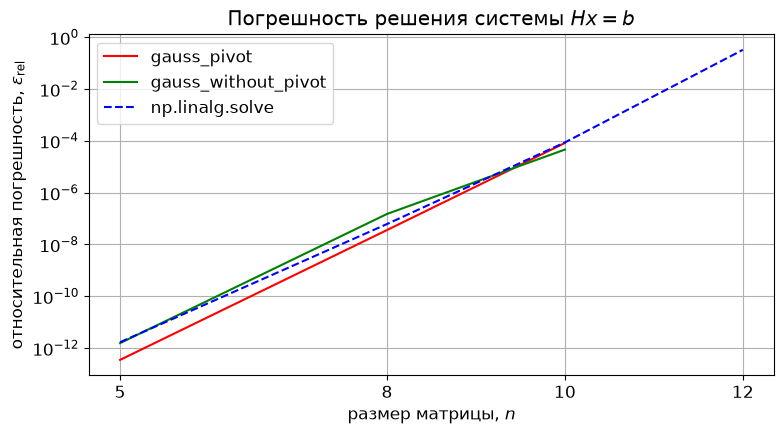

In [9]:
methods = ['gauss_pivot', 'gauss_without_pivot', 'np.linalg.solve']
styles  = ['r-', 'g-', 'b--']

# TODO: извлеките результаты из hilbert_results по каждому методу
relative_error_data = {}
for r in hilbert_results:
    relative_error_data[(r['n'], r['method'])] = r['rel_error']

# TODO: постройте три зависимости (два режима + np.linalg.solve)
# TODO: используйте plt.semilogy(...), legend(), grid(), xlabel(), ylabel()
for method, style in zip(methods, styles):
    y = [relative_error_data[(n, method)] for n in n_values]
    plt.semilogy(n_values, y, style, label=method)

plt.xlabel('размер матрицы, $n$')
plt.ylabel(r'относительная погрешность, $\varepsilon_{\mathrm{rel}}$')
plt.title('Погрешность решения системы $Hx=b$')
plt.xticks(n_values)
plt.grid(True, which='both')
plt.legend()
plt.tight_layout()
plt.show()
# TODO: при необходимости сохраните рисунок в PNG или PDF (см. ниже)

## 6. Повторное решение при одной матрице и нескольких правых частях

LU-разложение строится **один раз**, после чего каждая новая правая часть решается двумя треугольными подстановками. Сравните это с методом Гаусса, которому требуется заново выполнять исключение для каждой правой части.

### Задание 6

Создайте случайную невырожденную матрицу размерности $n=40$ и **$k=10$ различных правых частей**. Исходные данные должны быть одинаковыми в обоих экспериментах.

1. Измерьте **общее время** решения всех $k$ систем отдельными вызовами `gauss_solve`.
2. Измерьте время **одного** вызова `lu_decompose`, затем время решения всех $k$ систем через `lu_solve`.
3. Выведите время Гаусса, время разложения, время подстановок и суммарное время LU.
4. Сравните решения с `np.linalg.solve(A_big, B_big)` и убедитесь, что все правые части использованы одинаково.
5. Постройте небольшой столбчатый график времени двух подходов.

*Примечание:* время зависит от среды выполнения, поэтому при серьёзном анализе желательно повторить замер несколько раз. Для более наглядного эффекта можно дополнительно исследовать $k=100$, как на семинаре; в актуальной методичке обязательным этот эксперимент не назван.

In [10]:
n = 40
k = 100
rng = np.random.default_rng(2027)

A_big = rng.normal(size=(n, n))
A_big[np.diag_indices(n)] += np.sum(np.abs(A_big), axis=1) + 1.0
B_big = rng.normal(size=(n, k))   # каждый столбец — отдельная правая часть

# TODO: измерьте общее время k независимых вызовов gauss_solve
start_time = perf_counter()
for i in range(k):
    b = B_big[:, i]
    gauss_solve(A_big, b)
t_gauss = perf_counter() - start_time
print("'к' независимых вызовов gauss_solve:\t\t", t_gauss)

# TODO: измерьте время однократного lu_decompose(A_big)
start_time = perf_counter()
P, L, U = lu_decompose(A_big)
t_plu_fact = perf_counter() - start_time
print("время однократного lu_decompose:\t\t", t_plu_fact)

# TODO: измерьте время k вызовов lu_solve с готовыми P, L, U
start_time = perf_counter()
for i in range(k):
    b = B_big[:, i]
    lu_solve(P, L, U, b)
t_plu_solve = perf_counter() - start_time
print("время 'k' вызовов lu_solve с готовыми P, L, U:\t", t_plu_solve)

# TODO: сравните оба набора решений с np.linalg.solve(A_big, B_big)
start_time = perf_counter()
np.linalg.solve(A_big, B_big)
t_numpy = perf_counter() - start_time
print("время 'k' вызовов np.linalg.solve:\t\t", t_numpy)

'к' независимых вызовов gauss_solve:		 0.17405170000165526
время однократного lu_decompose:		 0.001485000000684522
время 'k' вызовов lu_solve с готовыми P, L, U:	 0.04527977399993688
время 'k' вызовов np.linalg.solve:		 0.0003398650005692616


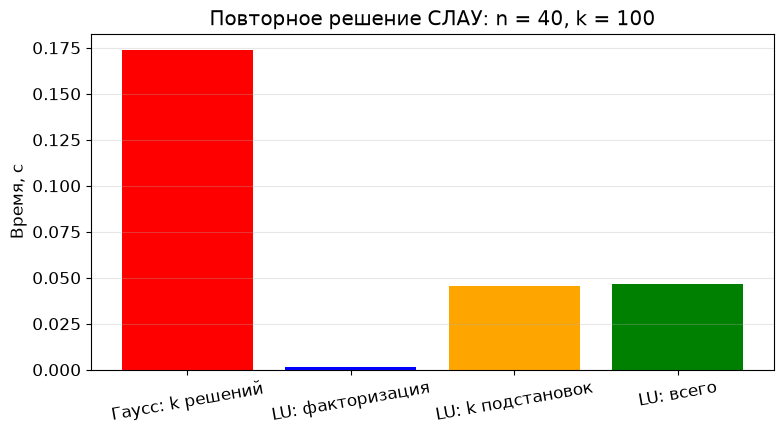

In [11]:
# TODO: постройте столбчатый график: Гаусс (всего) и LU (факторизация + решения)
t_lu_total = t_plu_fact + t_plu_solve
bars = plt.bar(["Гаусс: k решений", "LU: факторизация", "LU: k подстановок", "LU: всего"], 
               [t_gauss, t_plu_fact, t_plu_solve, t_lu_total], color=['red', 'blue', 'orange', 'green'])
plt.ylabel("Время, с")
plt.title(f"Повторное решение СЛАУ: n = {n}, k = {k}")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Дополнительные исследования (на доп балл)

### 7.1. Время работы в зависимости от размера системы

Для $n=10,20,40,80$ создайте воспроизводимые случайные невырожденные матрицы и измерьте время **собственных** реализаций метода Гаусса и LU-разложения. Сравните с `np.linalg.solve` и с `scipy.linalg.lu_factor` / `scipy.linalg.lu_solve`. Не сравнивайте только факторизацию со временем **полного** решения: фиксируйте, что именно вошло в замер. Если один прогон занимает более 30 секунд, прекратите последующие измерения этого метода и укажите ограничение в отчёте.

### 7.2. Влияние количества правых частей

Повторите задание 6 для $k=1,10,100$ и объясните, почему LU-разложение становится выгоднее при многократном использовании одной матрицы. На малых размерах накладные расходы Python могут исказить соотношение времени.

In [12]:
from scipy.linalg import lu_factor, lu_solve as scipy_lu_solve

n_values = [10, 20, 40, 80]
k_values = [1, 10, 100]

results = []
for n in n_values:
    for k in k_values:
        A_big = rng.normal(size=(n, n))
        A_big[np.diag_indices(n)] += np.sum(np.abs(A_big), axis=1) + 1.0
        B_big = rng.normal(size=(n, k))

        # gauss_solve k вызовов
        start_time = perf_counter()
        X_gauss = np.empty_like(B_big)
        for i in range(k):
            X_gauss[:, i] = gauss_solve(A_big, B_big[:, i])
        t_gauss = perf_counter() - start_time
        
        # print(f"'{k}' независимых вызовов gauss_solve:\t\t", t_gauss)
        results.append({"n": n, "k": k, "method": "gauss_solve",
                        "time_fact": None, "time_solve": t_gauss,
                        "time_total": t_gauss})

        # PLU: 1 факторизация + k подстановок
        start_time = perf_counter()
        P, L, U = lu_decompose(A_big)
        t_plu_fact = perf_counter() - start_time
        
        # print("время однократного lu_decompose:\t\t", t_plu_fact)

        start_time = perf_counter()
        X_plu = np.empty_like(B_big)
        for i in range(k):
            X_plu[:, i] = lu_solve(P, L, U, B_big[:, i])
        t_plu_solve = perf_counter() - start_time
        
        # print(f"время '{k}' вызовов lu_solve с готовыми P, L, U:\t", t_plu_solve)
        results.append({"n": n, "k": k, "method": "plu",
                        "time_fact": t_plu_fact, "time_solve": t_plu_solve,
                        "time_total": t_plu_fact + t_plu_solve})

        # numpy solve
        start_time = perf_counter()
        X_np = np.linalg.solve(A_big, B_big)
        t_numpy = perf_counter() - start_time
        
        # print(f"время np.linalg.solve (batched):\t\t", t_numpy)
        results.append({"n": n, "k": k, "method": "numpy_solve",
                        "time_fact": None, "time_solve": t_numpy,
                        "time_total": t_numpy})

        # scipy: lu_factor + k lu_solve
        start_time = perf_counter()
        lu_piv = lu_factor(A_big)
        t_scipy_fact = perf_counter() - start_time
        
        # print("время scipy.linalg.lu_factor:\t\t\t", t_scipy_fact)

        start_time = perf_counter()
        X_scipy = np.empty_like(B_big)
        for i in range(k):
            X_scipy[:, i] = scipy_lu_solve(lu_piv, B_big[:, i])
        t_scipy_solve = perf_counter() - start_time
        
        # print(f"время '{k}' вызовов scipy.linalg.lu_solve:\t", t_scipy_solve)
        results.append({"n": n, "k": k, "method": "scipy_plu",
                        "time_fact": t_scipy_fact, "time_solve": t_scipy_solve,
                        "time_total": t_scipy_fact + t_scipy_solve})    
    # print()
# results

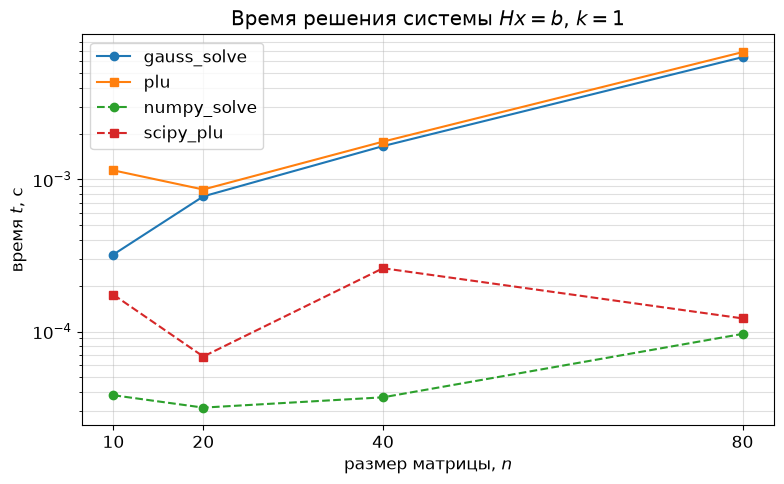

In [13]:
method_colors = {
    'gauss_solve': 'red',
    'plu':         'green',
    'numpy_solve': 'blue',
    'scipy_plu':   'orange',
}
methods = ['gauss_solve', 'plu', 'numpy_solve', 'scipy_plu']
styles = ['o-', 's-', 'o--', 's--']
k_styles = {1: 'o-', 10: 's--', 100: '^:'}

time = {(d['n'], d['k'], d['method']): d['time_total'] for d in results}
plt.figure(figsize=(8, 5))
for method, style in zip(methods, styles):
    y = [time[(n, 1, method)] for n in n_values]
    plt.semilogy(n_values, y, style, label=method)

plt.xlabel('размер матрицы, $n$')
plt.ylabel(r'время $t$, с')
plt.title(f'Время решения системы $Hx=b$, $k={1}$')
plt.xticks(n_values)
plt.grid(True, which='both', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

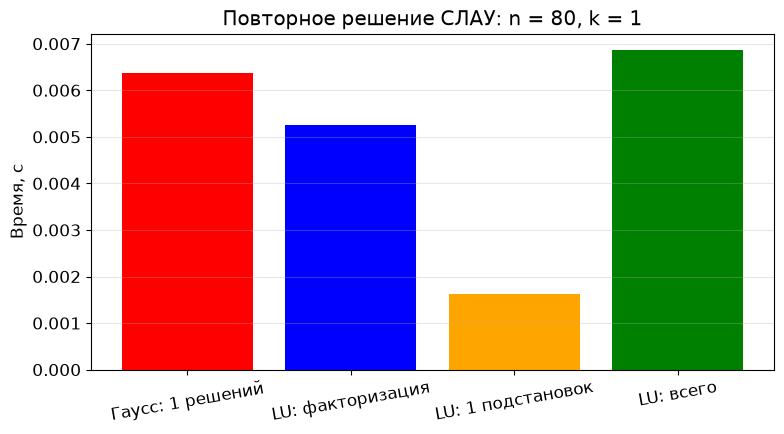

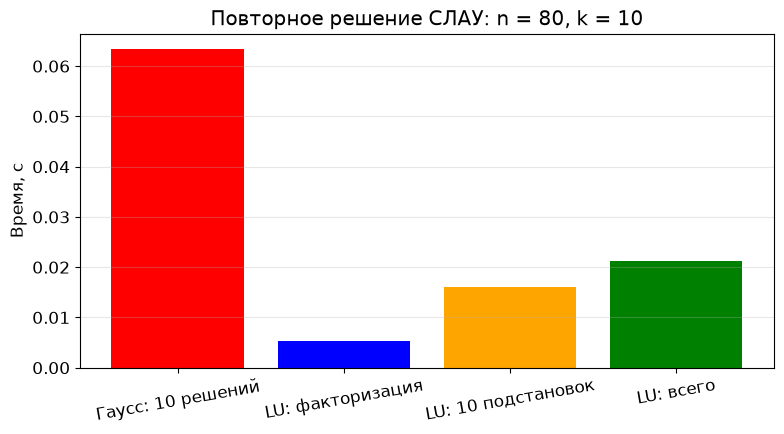

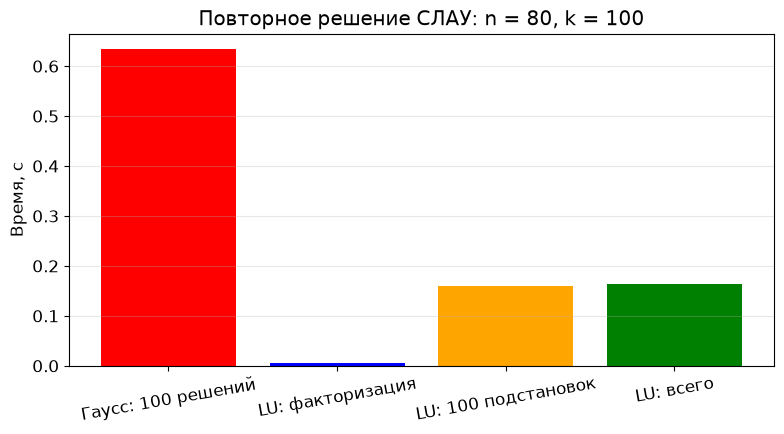

In [15]:
n = max(d['n'] for d in results)
rows = {(d['n'], d['k'], d['method']): d for d in results}

for k in sorted({d['k'] for d in results}):
    fact = rows[(n, k, 'plu')]['time_fact']
    solve = rows[(n, k, 'plu')]['time_solve']
    values = [rows[(n, k, 'gauss_solve')]['time_total'], fact, solve, fact + solve]
    labels = [f"Гаусс: {k} решений", "LU: факторизация", f"LU: {k} подстановок", "LU: всего"]

    plt.bar(labels, values, color=['red', 'blue', 'orange', 'green'])
    plt.ylabel("Время, с")
    plt.title(f"Повторное решение СЛАУ: n = {n}, k = {k}")
    plt.xticks(rotation=10)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. Вопросы для самопроверки

1. В чём различие прямого хода и обратной подстановки?
2. Что называется ведущим элементом? Почему он не должен быть слишком малым?
3. Что означает частичный выбор ведущего элемента и как он реализуется?
4. Почему Гаусс без перестановок останавливается для чётных вариантов этой работы?
5. Чем относительная ошибка решения отличается от невязки?
6. Какое разложение нужно проверять при перестановках строк: $A=LU$ или $PA=LU$?
7. Почему при перестановках строк меняется не только $U$, но и заполненная часть $L$?
8. Как число обусловленности связано с чувствительностью решения?
9. Почему малая невязка может сопровождаться большой ошибкой решения?
10. Почему LU выгодно при повторном решении с одной матрицей и разными правыми частями?
11. Какова оценка вычислительной сложности Гаусса и LU? Какая стоимость у подстановок?
12. Почему при сбое метода нельзя вносить в таблицу фиктивные нули?